In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

load_dotenv("../.env")
url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
)
engine = create_engine(url)

date_cols = ["order_purchase_timestamp", "order_delivered_customer_date",
             "order_estimated_delivery_date"]
orders = pd.read_csv("../data/cleaned/orders_features.csv", parse_dates=date_cols)
reviews = pd.read_sql("SELECT * FROM order_reviews", engine)
payments = pd.read_sql("SELECT * FROM order_payments", engine)

sns.set_theme(style="whitegrid")
delivered = orders[orders["order_status"] == "delivered"]
print("Ready!", orders.shape)

Ready! (99441, 17)


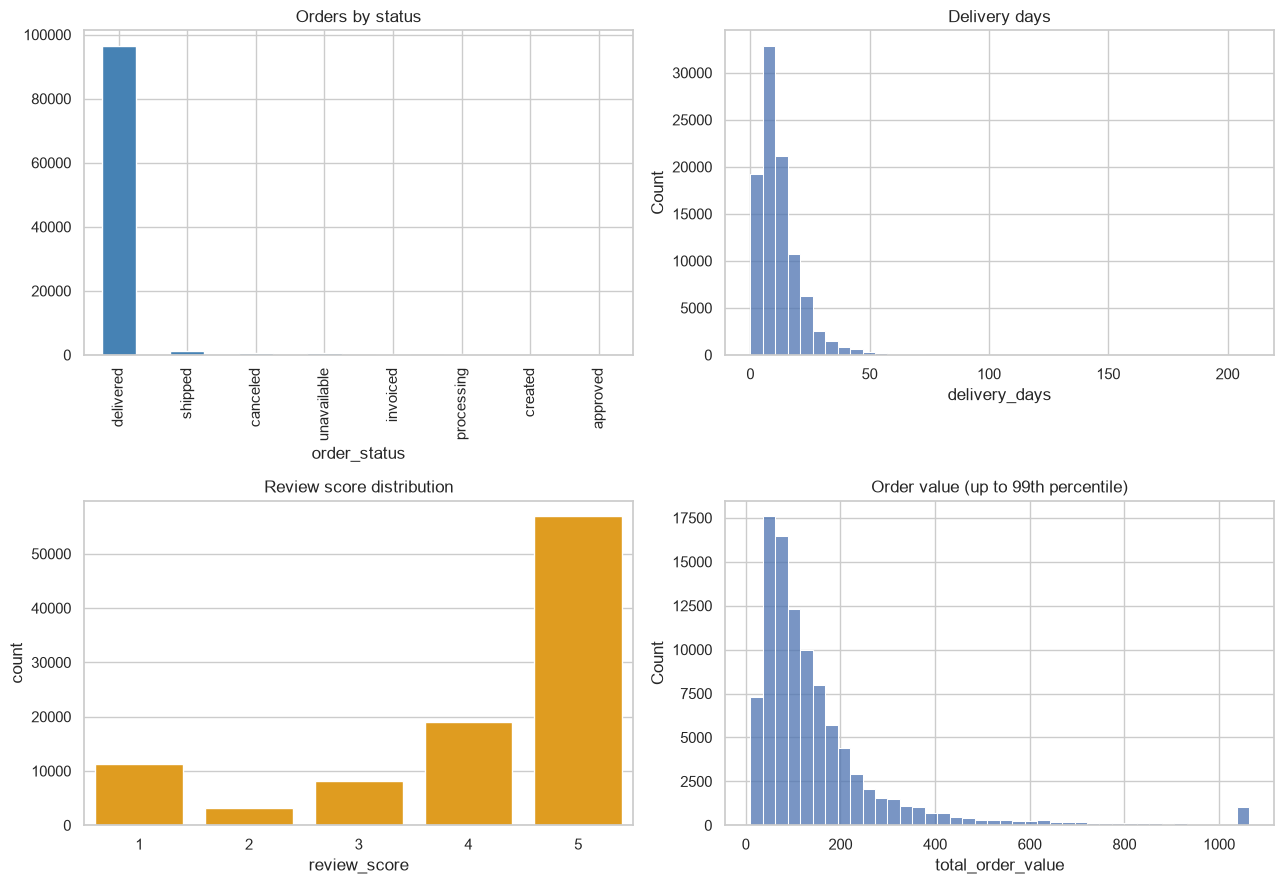

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

orders["order_status"].value_counts().plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Orders by status")

sns.histplot(delivered["delivery_days"].dropna(), bins=40, ax=axes[0, 1])
axes[0, 1].set_title("Delivery days")

sns.countplot(x="review_score", data=reviews, ax=axes[1, 0], color="orange")
axes[1, 0].set_title("Review score distribution")

cap = orders["total_order_value"].quantile(0.99)
sns.histplot(orders["total_order_value"].dropna().clip(upper=cap), bins=40, ax=axes[1, 1])
axes[1, 1].set_title("Order value (up to 99th percentile)")

plt.tight_layout()
plt.show()

In [4]:
print("Median delivery days:", delivered["delivery_days"].median())
print("Median order value:", round(orders["total_order_value"].median(), 2))
print("Mean order value:", round(orders["total_order_value"].mean(), 2))
print("Share of 5-star reviews:", round((reviews["review_score"] == 5).mean() * 100, 1), "%")
print("Share of 1-star reviews:", round((reviews["review_score"] == 1).mean() * 100, 1), "%")

Median delivery days: 10.0
Median order value: 105.29
Mean order value: 160.58
Share of 5-star reviews: 57.8 %
Share of 1-star reviews: 11.5 %


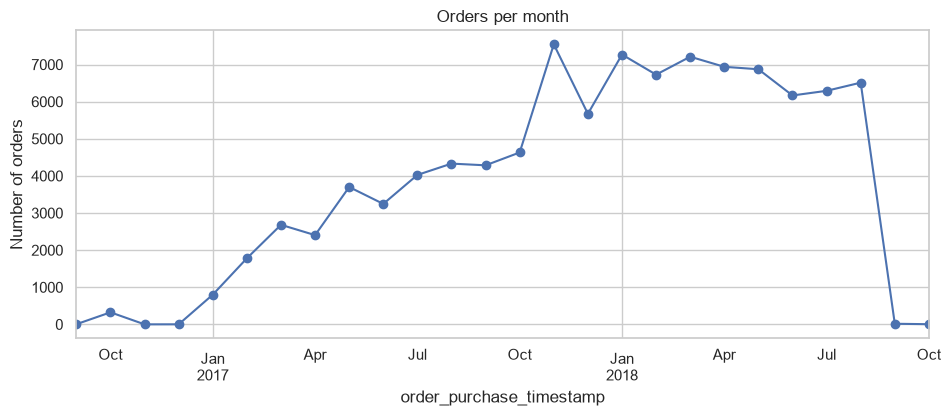

In [5]:
monthly = (orders.set_index("order_purchase_timestamp")
           .resample("ME")["order_id"].count())
monthly.plot(figsize=(11, 4), marker="o", title="Orders per month")
plt.ylabel("Number of orders")
plt.show()

                mean  count
is_delayed                 
False       4.292365  89248
True        2.269926   6361


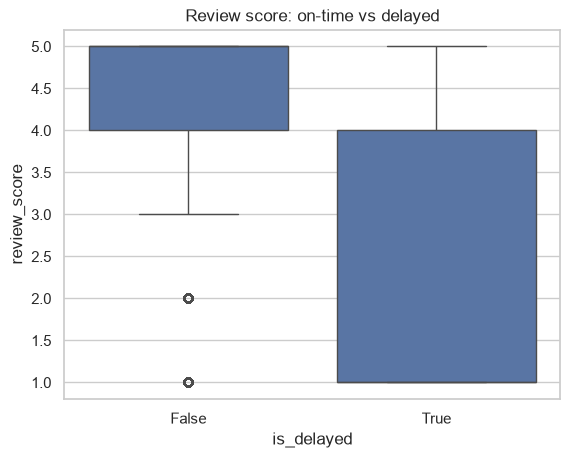

In [6]:
review_orders = delivered.merge(reviews[["order_id", "review_score"]], on="order_id", how="inner")

print(review_orders.groupby("is_delayed")["review_score"].agg(["mean", "count"]))

sns.boxplot(x="is_delayed", y="review_score", data=review_orders)
plt.title("Review score: on-time vs delayed")
plt.show()

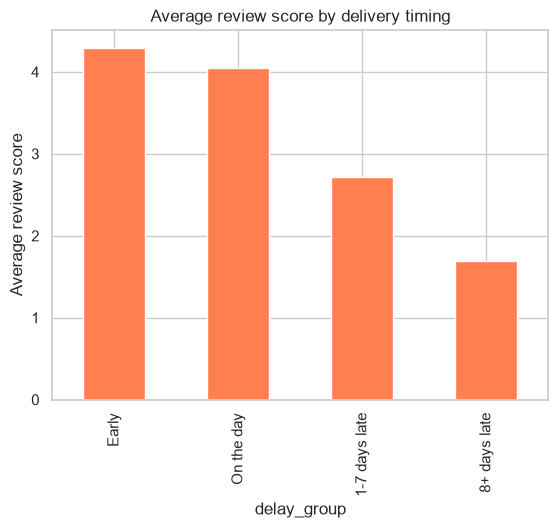

In [7]:
review_orders["delay_group"] = pd.cut(
    review_orders["delivery_delay_days"],
    bins=[-100, -1, 0, 7, 500],
    labels=["Early", "On the day", "1-7 days late", "8+ days late"],
)
review_orders.groupby("delay_group", observed=True)["review_score"].mean().plot(
    kind="bar", color="coral", title="Average review score by delivery timing")
plt.ylabel("Average review score")
plt.show()